# PRISMA Nanonis 10 Samples

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from os.path import join

from prisma.calc.dim_analysis import rescale_bounds_inv
from prisma.file import load_np_val, save_np_val
from prisma.nlr import curve_fit_series, get_ML_cov_sp
from prisma.bnlr import optimize_posterior
from prisma.physics_models.python import Ibeem_vector, Ibeem_vector_f_w_vectorized
from prisma.physics_models.jax import beem_integral_f_vector_j
from prisma.plot import plot_hist_series, plot_spectrum_series_sort, \
    plot_spectrum_series_fit_sort, set_rc_journal_const_wh

In [3]:
np.random.seed(0)

import jax
jax.config.update('jax_enable_x64', True)

In [4]:
base_dir = r"C:\Users\djbasil\Documents\Data\BEEM_Data"
data_dir = join(base_dir, "Nanonis_BNLR_Measure_Tap_ct_100_Ibeem_rescale_s_10_rp_0")
figure_dir = join(base_dir, "Figure_Data")

In [5]:
set_rc_journal_const_wh()

# Samples

In [6]:
spectrum_series = load_np_val(data_dir, 'x_n_spectr_series_100_Ibeem.npy')

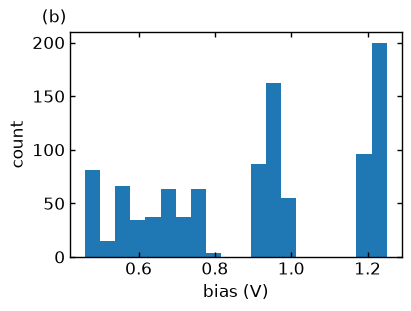

In [7]:
plot_hist_series(spectrum_series.flatten(), bins=20,
                 xlabel="bias (V)",
                #  title="Sample Locations",
                 id="(b)",
                 f_save=join(figure_dir, "PRISMA_nanonis_10_samples.pdf"))

In [8]:
t_series = load_np_val(data_dir, 't_n_spectr_series_100_Ibeem.npy')

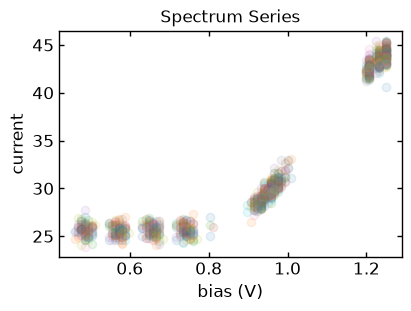

In [9]:
plot_spectrum_series_sort(spectrum_series, t_series, xlabel="bias (V)", ylabel="current", title="Spectrum Series")

In [10]:
in_min = 0.
in_max = .2
out_min = 0.
out_max = 100.

In [11]:
t_series_inv = rescale_bounds_inv(t_series, in_min, in_max, out_min, out_max)

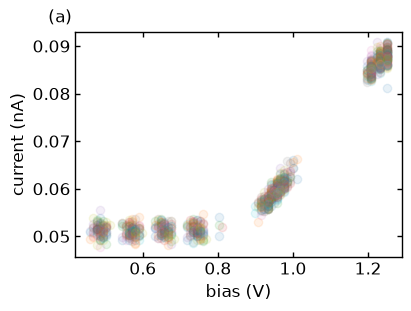

In [12]:
plot_spectrum_series_sort(spectrum_series, t_series_inv,
                          xlabel="bias (V)",
                          ylabel="current (nA)",
                        #   title="I/V Spectra",
                          id="(a)",
                          f_save=join(figure_dir, "PRISMA_nanonis_10_spectrum.pdf"))

# Barrier

In [13]:
m_prior_series = load_np_val(data_dir, 'm_prior_spectr_series_100_Ibeem.npy')

In [14]:
barrier_fit = m_prior_series[:, -1, 1]

In [15]:
barrier_fit

array([0.87097354, 0.8637006 , 0.86845259, 0.8833367 , 0.86233165,
       0.86574033, 0.86815826, 0.88529124, 0.85389828, 0.87334345,
       0.86572479, 0.85750539, 0.8600901 , 0.86764895, 0.86325216,
       0.85814456, 0.85643088, 0.88323356, 0.86318018, 0.86081687,
       0.87861063, 0.87038041, 0.8712778 , 0.86263031, 0.85381754,
       0.877667  , 0.87563283, 0.86668497, 0.86380391, 0.8552704 ,
       0.85683447, 0.87389056, 0.87438442, 0.85974201, 0.86194061,
       0.85110472, 0.87292488, 0.86386681, 0.87319479, 0.86845933,
       0.88537412, 0.87230604, 0.87246805, 0.87665299, 0.87880487,
       0.85913339, 0.86880862, 0.88183559, 0.87364105, 0.87051445,
       0.8701605 , 0.86633777, 0.87245078, 0.87992014, 0.86508549,
       0.85209682, 0.85714073, 0.85638483, 0.86356639, 0.8668906 ,
       0.87135544, 0.86270784, 0.86945846, 0.86259451, 0.86977826,
       0.86941119, 0.8679024 , 0.86084327, 0.85530672, 0.84800385,
       0.87383104, 0.85964612, 0.88449072, 0.88178936, 0.87241

In [16]:
np.mean(barrier_fit)

np.float64(0.8685449358463667)

In [17]:
np.std(barrier_fit)

np.float64(0.008782161016806232)

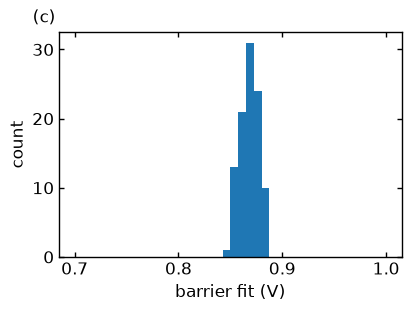

In [18]:
plot_hist_series(barrier_fit, bins=40, range=(.7, 1.),
                 xlabel="barrier fit (V)",
                #  title="Barrier Fit",
                 id="(c)",
                 f_save=join(figure_dir, "PRISMA_nanonis_10_barrier.pdf"))

# Spectrum Fit

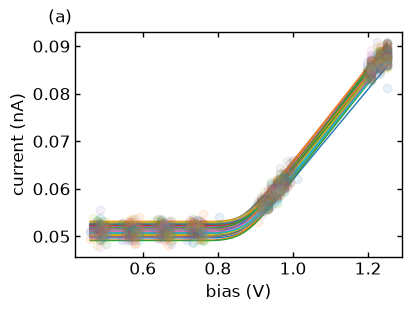

In [19]:
plot_spectrum_series_fit_sort(spectrum_series, t_series_inv,
                              np.linspace(np.min(spectrum_series),
                                          np.max(spectrum_series),
                                          100),
                              m_prior_series[:, -1],
                              beem_integral_f_vector_j,
                              scale_bounds=(in_min, in_max, out_min, out_max),
                              xlabel="bias (V)",
                              ylabel="current (nA)",
                              #  title="I/V Spectra",
                              f_save=join(figure_dir, "PRISMA_nanonis_10_spectrum_fit.pdf"),
                              id="(a)")

# Confidence Posterior

In [20]:
var_prior_series = load_np_val(data_dir, 'var_prior_spectr_series100_Ibeem.npy')

In [21]:
barrier_stddev = np.sqrt(var_prior_series[:, -1, 1, 1])

In [22]:
barrier_stddev

array([0.0362164 , 0.03532593, 0.03496145, 0.03451404, 0.03485973,
       0.035064  , 0.03570157, 0.03594931, 0.03558703, 0.03514418,
       0.03495559, 0.03497854, 0.03551117, 0.03453811, 0.03587793,
       0.03482544, 0.03590688, 0.03395006, 0.03551638, 0.03512162,
       0.03450882, 0.0347442 , 0.03576359, 0.03517737, 0.0352392 ,
       0.0344576 , 0.03505909, 0.03505135, 0.03539016, 0.03602699,
       0.03600104, 0.03612062, 0.03430656, 0.03521782, 0.03528911,
       0.0365584 , 0.03487434, 0.03595064, 0.03503728, 0.03507436,
       0.03330245, 0.03511941, 0.03464779, 0.03508811, 0.03159706,
       0.03543517, 0.03444093, 0.03562599, 0.03243589, 0.0347818 ,
       0.0355635 , 0.03563603, 0.03452967, 0.03436213, 0.03526634,
       0.03519659, 0.03473598, 0.03461407, 0.03531623, 0.03455938,
       0.03438309, 0.03424496, 0.03493854, 0.03474658, 0.03369396,
       0.03467148, 0.03481902, 0.03446765, 0.03489343, 0.03512145,
       0.0323887 , 0.03477751, 0.03357117, 0.03487765, 0.03516

In [23]:
np.mean(barrier_stddev)

np.float64(0.034928156124241785)

In [24]:
np.std(barrier_stddev)

np.float64(0.0008125622120776138)

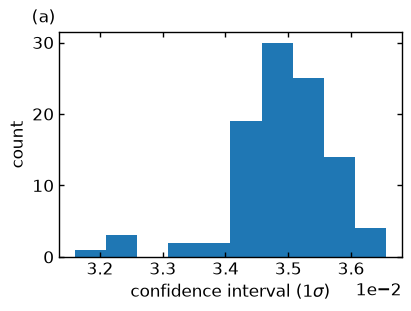

In [25]:
plot_hist_series(barrier_stddev, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier Posterior Confidence",
                 id="(a)",
                 f_save=join(figure_dir, "PRISMA_nanonis_10_barrier_stddev_posterior.pdf"))

# Confidence NLR

In [26]:
p0 = [23., .8, 5e-3]

In [27]:
w_cf_series_np, w_cov_cf_series_np = curve_fit_series(spectrum_series, t_series, p0, Ibeem_vector)

In [28]:
barrier_cf = w_cf_series_np[:, 1]

In [29]:
barrier_cf

array([0.86663544, 0.86333959, 0.87022797, 0.88474603, 0.86270567,
       0.86816301, 0.86897724, 0.88876374, 0.84907857, 0.87532991,
       0.86735598, 0.85673145, 0.85952213, 0.87103386, 0.86483306,
       0.85766553, 0.85584661, 0.88546926, 0.86074996, 0.85119068,
       0.88052476, 0.87173748, 0.87176774, 0.86081618, 0.85075131,
       0.88055478, 0.87550313, 0.86794825, 0.86411746, 0.85215281,
       0.85311595, 0.8717575 , 0.87534652, 0.86060583, 0.86242787,
       0.8416842 , 0.87387319, 0.86226494, 0.87274689, 0.86883628,
       0.89086594, 0.87645734, 0.8764726 , 0.87658263, 0.8857856 ,
       0.85691804, 0.87037348, 0.88387485, 0.87704193, 0.8692087 ,
       0.86910664, 0.8644853 , 0.87482486, 0.88050427, 0.8628169 ,
       0.8504821 , 0.85726028, 0.85418126, 0.86434507, 0.87013504,
       0.87163222, 0.85959206, 0.87228681, 0.86227199, 0.87229575,
       0.87410386, 0.86910768, 0.86133829, 0.85497939, 0.84422977,
       0.87866156, 0.86104966, 0.89042639, 0.88381764, 0.87349

In [30]:
np.mean(barrier_cf)

np.float64(0.8687741913464408)

In [31]:
np.std(barrier_cf)

np.float64(0.010690178238335393)

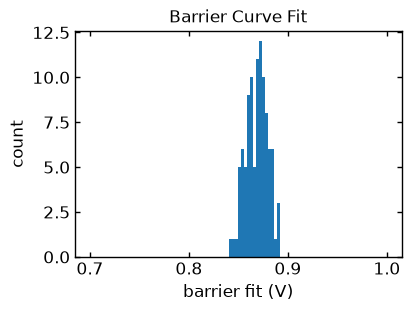

In [32]:
plot_hist_series(barrier_cf, bins=100, range=(.7, 1.), xlabel="barrier fit (V)", title="Barrier Curve Fit")

In [33]:
barrier_stddev_cf = np.sqrt(w_cov_cf_series_np[:, 1, 1])

In [34]:
barrier_stddev_cf

array([0.02412527, 0.01013696, 0.00992511, 0.01174301, 0.00811729,
       0.0076763 , 0.02040924, 0.01148829, 0.00671699, 0.00714877,
       0.00614374, 0.01100241, 0.01224601, 0.0100559 , 0.01214896,
       0.01324391, 0.01631526, 0.00455323, 0.01625206, 0.01821318,
       0.00735179, 0.00915263, 0.01075723, 0.01018212, 0.01003074,
       0.00623353, 0.01030232, 0.01337456, 0.00867036, 0.0091505 ,
       0.00889815, 0.01619292, 0.01530012, 0.00959134, 0.01349818,
       0.01460951, 0.00895093, 0.01036924, 0.00801343, 0.00922054,
       0.0081666 , 0.0123298 , 0.01175303, 0.00841819, 0.00992687,
       0.00547121, 0.01214521, 0.0116817 , 0.01422327, 0.00860298,
       0.00856638, 0.0075717 , 0.00991075, 0.00587705, 0.01127617,
       0.01332852, 0.01141495, 0.01220407, 0.01359717, 0.00963951,
       0.00829403, 0.00915147, 0.00793381, 0.0084029 , 0.01003144,
       0.00940295, 0.01158472, 0.0089371 , 0.01258272, 0.01176156,
       0.01034288, 0.00986522, 0.00577917, 0.01183035, 0.00976

In [35]:
np.mean(barrier_stddev_cf)

np.float64(0.010584679321593331)

In [36]:
np.std(barrier_stddev_cf)

np.float64(0.0032332036302222433)

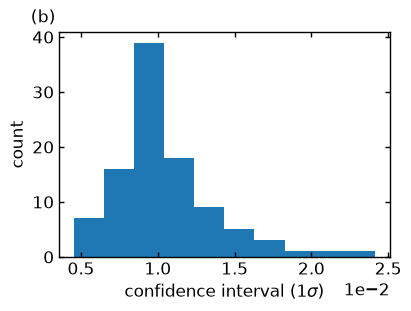

In [37]:
plot_hist_series(barrier_stddev_cf, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier NLR Confidence",
                 id="(b)",
                 f_save=join(figure_dir, "PRISMA_nanonis_10_barrier_stddev_NLR.pdf"))

# Confidence FIM

In [38]:
series_ct = len(spectrum_series)
param_ct = m_prior_series.shape[2]

In [39]:
m_prior_cov_ML_series = np.empty((series_ct, param_ct, param_ct))
for i in range(series_ct):
    m_prior_cov_ML_series[i] = get_ML_cov_sp(Ibeem_vector_f_w_vectorized, spectrum_series[i], m_prior_series[i, -1], t_n=t_series[i], absolute_sigma=False)

In [40]:
# save_np_val(data_dir, 'm_prior_cov_ML_spectr_series_100_Ibeem.npy', m_prior_cov_ML_series)

In [41]:
barrier_stddev_ML = np.sqrt(m_prior_cov_ML_series[:, 1, 1])

In [42]:
barrier_stddev_ML

array([0.02369975, 0.01011902, 0.01002559, 0.01173946, 0.00811981,
       0.00777726, 0.02046625, 0.01168981, 0.00729871, 0.00727128,
       0.00619861, 0.01102663, 0.01220842, 0.01031586, 0.01226597,
       0.01321287, 0.01632346, 0.00473813, 0.01613958, 0.01770692,
       0.00743798, 0.00920601, 0.01078746, 0.01013057, 0.01005692,
       0.00627994, 0.01027945, 0.0134546 , 0.00866471, 0.00935659,
       0.00913564, 0.01612937, 0.01533565, 0.00960753, 0.01349052,
       0.01467399, 0.00901174, 0.01058123, 0.00806337, 0.00922256,
       0.00890717, 0.01274757, 0.01216204, 0.00842274, 0.01100203,
       0.00571899, 0.01225326, 0.01167111, 0.01455004, 0.00860619,
       0.00857774, 0.00767845, 0.01008213, 0.00589779, 0.01121486,
       0.01323488, 0.01140076, 0.0121446 , 0.01362391, 0.00988618,
       0.00831793, 0.00916262, 0.00793777, 0.00841136, 0.01010328,
       0.00987238, 0.01162468, 0.00894185, 0.01254105, 0.0121006 ,
       0.01093327, 0.00991635, 0.00648615, 0.01200592, 0.00983

In [43]:
np.mean(barrier_stddev_ML)

np.float64(0.010681746154447478)

In [44]:
np.std(barrier_stddev_ML)

np.float64(0.003172971874612112)

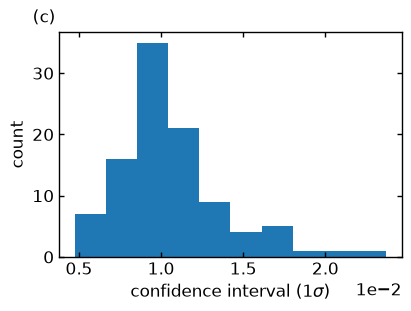

In [45]:
plot_hist_series(barrier_stddev_ML, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier FIM Confidence",
                 id="(c)",
                 f_save=join(figure_dir, "PRISMA_nanonis_10_barrier_stddev_FIM_uq.pdf"))

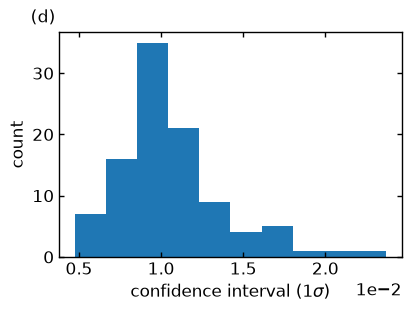

In [46]:
plot_hist_series(barrier_stddev_ML, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier FIM Confidence",
                 id="(d)",
                 f_save=join(figure_dir, "PRISMA_nanonis_10_barrier_stddev_FIM.pdf"))

# Optimize Posterior

In [47]:
sigma_f = 2.
var_f = sigma_f**2 # function variance
beta = (1. / var_f) # function precision

In [48]:
measure_ct = spectrum_series.shape[1]

In [49]:
m_opt_series = np.empty((series_ct, param_ct))
var_opt_series = np.empty((series_ct, param_ct, param_ct))
Phi_opt_series = np.empty((series_ct, measure_ct, param_ct))
for i in range(series_ct):
    Phi_opt_series[i], m_opt_series[i], var_opt_series[i] \
        = optimize_posterior(beem_integral_f_vector_j,
                             beta, spectrum_series[i], t_series[i],
                             m_prior_series[i, 0], var_prior_series[i, 0],
                             eps=1e-4, i_max=1000)

In [50]:
barrier_fit_opt = m_opt_series[:, 1]

In [51]:
barrier_fit_opt

array([0.86643969, 0.8630593 , 0.87007218, 0.88458102, 0.86258876,
       0.86789225, 0.86883045, 0.88845224, 0.84891622, 0.87518472,
       0.86705826, 0.85658828, 0.85939825, 0.87084765, 0.86469217,
       0.85737191, 0.85567531, 0.88527775, 0.86063518, 0.85122193,
       0.8804843 , 0.87156671, 0.87163996, 0.86068384, 0.85058254,
       0.88021368, 0.87538623, 0.86779606, 0.86383962, 0.85187198,
       0.85298083, 0.87160371, 0.87523562, 0.86050312, 0.86230067,
       0.84152421, 0.8737543 , 0.8622834 , 0.87262286, 0.86870271,
       0.89069005, 0.87632784, 0.8763062 , 0.87645067, 0.88559921,
       0.8568004 , 0.87035807, 0.88355861, 0.8768351 , 0.86909078,
       0.86897023, 0.86418822, 0.87467241, 0.88039128, 0.86270295,
       0.8503533 , 0.85709008, 0.85421535, 0.86405481, 0.8699868 ,
       0.87146687, 0.85960354, 0.87201347, 0.86215035, 0.87204183,
       0.87395829, 0.8688358 , 0.86120403, 0.85483215, 0.84413545,
       0.87853414, 0.8609122 , 0.89012585, 0.88371893, 0.87337

In [52]:
np.mean(barrier_fit_opt)

np.float64(0.8686137225208519)

In [53]:
np.std(barrier_fit_opt)

np.float64(0.010678788251717001)

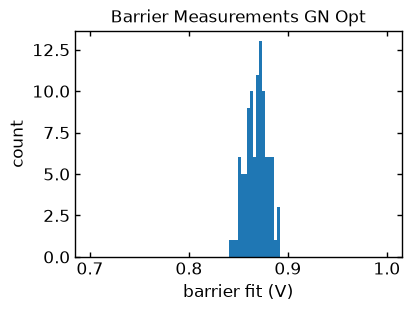

In [54]:
plot_hist_series(barrier_fit_opt, bins=100, range=(.7, 1.), xlabel="barrier fit (V)", title="Barrier Measurements GN Opt")

In [55]:
barrier_stddev_opt = np.sqrt(var_opt_series[:, 1, 1])

In [56]:
barrier_stddev_opt

array([0.03962784, 0.03685802, 0.03530883, 0.03609552, 0.03568668,
       0.03538768, 0.03611451, 0.03599636, 0.03919685, 0.03518075,
       0.03557339, 0.03548659, 0.03639603, 0.03467223, 0.0356878 ,
       0.03647021, 0.03647369, 0.0346451 , 0.03718054, 0.03948669,
       0.03501627, 0.03544467, 0.03629158, 0.03695171, 0.03799151,
       0.03445188, 0.03631196, 0.03544365, 0.03674612, 0.03866775,
       0.03842669, 0.03840135, 0.03578944, 0.03568916, 0.03612845,
       0.04116711, 0.03587964, 0.03752723, 0.03620904, 0.03598372,
       0.03365561, 0.03454138, 0.03430966, 0.03565201, 0.03098002,
       0.03685436, 0.03503736, 0.03651583, 0.03279062, 0.03568392,
       0.03671891, 0.03756755, 0.03503865, 0.03563373, 0.03720671,
       0.03690154, 0.03566601, 0.03702681, 0.03609224, 0.03474181,
       0.03531497, 0.03690984, 0.034466  , 0.03586611, 0.03520515,
       0.03401182, 0.03508498, 0.03537283, 0.03632416, 0.03755957,
       0.03191336, 0.03488726, 0.03379389, 0.0350263 , 0.03557

In [57]:
np.mean(barrier_stddev_opt)

np.float64(0.03602410088138444)

In [58]:
np.std(barrier_stddev_opt)

np.float64(0.0015280293443182766)

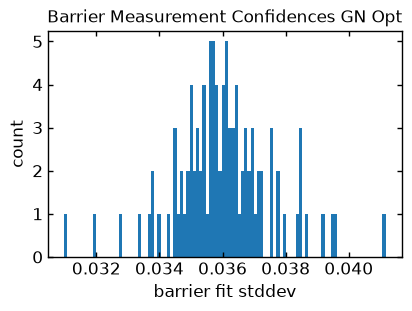

In [59]:
plot_hist_series(barrier_stddev_opt, bins=100, xlabel="barrier fit stddev", title="Barrier Measurement Confidences GN Opt")

In [60]:
# save_np_val(data_dir, 'Phi_opt_spectr_series_100_Ibeem.npy', Phi_opt_series)

In [61]:
# save_np_val(data_dir, 'm_opt_spectr_series_100_Ibeem.npy', m_opt_series)

In [62]:
# save_np_val(data_dir, 'var_opt_spectr_series_100_Ibeem.npy', var_opt_series)

# Optimize Posterior Pre-Trained

In [63]:
m_pt = np.mean(m_prior_series[:, -1], axis=0)

In [64]:
var_pt = np.diag(np.std(m_prior_series[:, -1], axis=0)**2)

In [65]:
m_opt_pt_series = np.empty((series_ct, param_ct))
var_opt_pt_series = np.empty((series_ct, param_ct, param_ct))
Phi_opt_pt_series = np.empty((series_ct, measure_ct, param_ct))
for i in range(series_ct):
    Phi_opt_pt_series[i], m_opt_pt_series[i], var_opt_pt_series[i] \
        = optimize_posterior(beem_integral_f_vector_j,
                             beta, spectrum_series[i], t_series[i],
                             m_pt, var_pt,
                             eps=1e-4, i_max=1000)

In [66]:
barrier_fit_opt_pt = m_opt_pt_series[:, 1]

In [67]:
barrier_fit_opt_pt

array([0.86704317, 0.86346464, 0.86955813, 0.88391031, 0.86300475,
       0.86619839, 0.86903669, 0.88793869, 0.84939064, 0.8747171 ,
       0.8664256 , 0.85698536, 0.85980721, 0.86776312, 0.86478394,
       0.85777193, 0.85610482, 0.8847164 , 0.86108916, 0.85180116,
       0.87999177, 0.87086417, 0.87177959, 0.86118825, 0.85104297,
       0.87979273, 0.8752128 , 0.86758319, 0.86424597, 0.85226642,
       0.85343176, 0.87314152, 0.87468428, 0.86090784, 0.86338225,
       0.84206234, 0.8733531 , 0.86546454, 0.87242924, 0.86880988,
       0.89009798, 0.87586181, 0.87583756, 0.87603938, 0.88519262,
       0.85722025, 0.86983773, 0.88300672, 0.87641527, 0.86894343,
       0.87024003, 0.86679128, 0.87420285, 0.87994744, 0.8659017 ,
       0.85081245, 0.85750081, 0.85472505, 0.86431707, 0.86825675,
       0.87012702, 0.86010591, 0.86978988, 0.86256486, 0.86888043,
       0.87027818, 0.86697452, 0.86156237, 0.85529516, 0.84451431,
       0.87805583, 0.86070234, 0.88963845, 0.8831724 , 0.87297

In [68]:
np.mean(barrier_fit_opt_pt)

np.float64(0.868558882647543)

In [69]:
np.std(barrier_fit_opt_pt)

np.float64(0.010259014269053892)

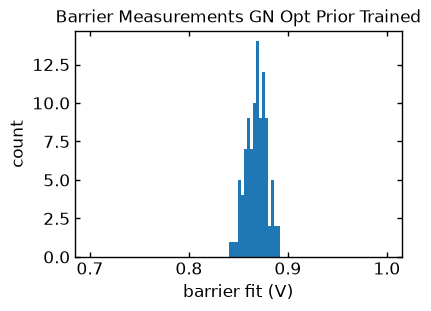

In [70]:
plot_hist_series(barrier_fit_opt_pt, bins=100, range=(.7, 1.), xlabel="barrier fit (V)", title="Barrier Measurements GN Opt Prior Trained")

In [71]:
barrier_stddev_opt_pt = np.sqrt(var_opt_pt_series[:, 1, 1])

In [72]:
barrier_stddev_opt_pt

array([0.00806586, 0.00804278, 0.00798291, 0.00798914, 0.00800701,
       0.00799931, 0.00800916, 0.00800431, 0.00810888, 0.00798476,
       0.00800226, 0.00799893, 0.00802957, 0.00797066, 0.00799622,
       0.00802734, 0.00802748, 0.00795212, 0.0080514 , 0.00809339,
       0.00798421, 0.00799117, 0.00801308, 0.00802649, 0.00807262,
       0.00796979, 0.00801934, 0.00799113, 0.00803884, 0.00810558,
       0.00809117, 0.00805912, 0.00799067, 0.0080115 , 0.00801299,
       0.00814067, 0.00800979, 0.00805089, 0.00802011, 0.00801232,
       0.00789921, 0.00796063, 0.00795101, 0.00801287, 0.00788854,
       0.00804975, 0.00796556, 0.00802174, 0.00796182, 0.00801005,
       0.00804188, 0.00806161, 0.00797842, 0.00798944, 0.00802667,
       0.00802704, 0.00799058, 0.00802528, 0.00801762, 0.00796605,
       0.00798059, 0.00803937, 0.00797462, 0.00801341, 0.00799008,
       0.00795081, 0.00798844, 0.00799393, 0.00801227, 0.00808551,
       0.00791813, 0.0079832 , 0.00790696, 0.00797403, 0.00800

In [73]:
np.mean(barrier_stddev_opt_pt)

np.float64(0.008010939449446215)

In [74]:
np.std(barrier_stddev_opt_pt)

np.float64(4.419964305174851e-05)

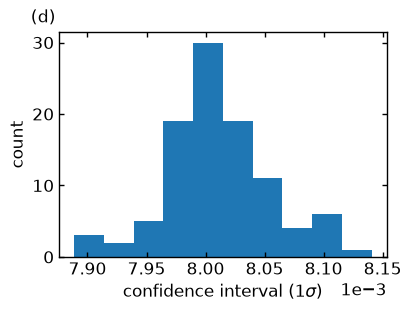

In [75]:
plot_hist_series(barrier_stddev_opt_pt, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier Pre-Trained Prior Confidence",
                 id="(d)",
                 f_save=join(figure_dir, "PRISMA_nanonis_10_barrier_stddev_opt_pretrain.pdf"))

In [76]:
# save_np_val(data_dir, 'Phi_opt_pt_spectr_series_100_Ibeem.npy', Phi_opt_pt_series)

In [77]:
# save_np_val(data_dir, 'm_opt_pt_spectr_series_100_Ibeem.npy', m_opt_pt_series)

In [78]:
# save_np_val(data_dir, 'var_opt_pt_spectr_series_100_Ibeem.npy', var_opt_pt_series)